## Global Financial Markets Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "global_financial_markets_2000_Now.csv"
df = pd.read_csv(csv_path)

### 1. Structural overview

In [2]:
print("Dataset shape (rows, columns):", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nColumn types and non-missing counts:")
df.info(memory_usage="deep")

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

Dataset shape (rows, columns): (192010, 10)

Column names:
['date', 'open', 'high', 'low', 'close', 'volume', 'symbol', 'asset_name', 'asset_type', 'region']

Column types and non-missing counts:
<class 'pandas.DataFrame'>
RangeIndex: 192010 entries, 0 to 192009
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   date        192010 non-null  str    
 1   open        192010 non-null  float64
 2   high        192010 non-null  float64
 3   low         192010 non-null  float64
 4   close       192010 non-null  float64
 5   volume      192010 non-null  int64  
 6   symbol      192010 non-null  str    
 7   asset_name  192010 non-null  str    
 8   asset_type  192010 non-null  str    
 9   region      192010 non-null  str    
dtypes: float64(4), int64(1), str(5)
memory usage: 21.8 MB

First five rows:


,date,open,high,low,close,volume,symbol,asset_name,asset_type,region
0,2000-01-03,1469.2500,1478.0000,1438.3600,1455.2200,931800000,^GSPC,S&P500,Stock Index,Global
1,2000-01-03,6961.7202,7159.3301,6720.8701,6750.7598,43072500,^GDAXI,DAX,Stock Index,Global
2,2000-01-03,0.0098,0.0099,0.0097,0.0098,0,JPYUSD=X,JPY/USD,Currency,Global
3,2000-01-03,17057.6992,17426.1602,17057.6992,17369.6309,0,^HSI,HSI,Stock Index,Global
4,2000-01-03,5209.5400,5384.6602,5209.5400,5375.1099,0,^BSESN,SENSEX,Stock Index,Global



Last five rows:


,date,open,high,low,close,volume,symbol,asset_name,asset_type,region
192005,2026-11-13,0.0063,0.0063,0.0062,0.0063,0,JPYUSD=X,JPY/USD,Currency,Global
192006,2026-11-13,25209.8496,25246.3496,25054.4004,25144.3008,239600,^NSEI,NIFTY50,Stock Index,Global
192007,2026-11-13,71342.9688,71428.5312,67653.0703,68249.2734,42985296506,BTC-USD,Bitcoin,Cryptocurrency,Global
192008,2026-11-13,656.0533,657.3438,625.3123,629.4333,1427117308,BNB-USD,BNB,Cryptocurrency,Global
192009,2026-11-13,0.1499,0.1499,0.1499,0.1499,0,CNYUSD=X,CNY/USD,Currency,Global


In [3]:
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})

display(missing_summary.sort_values("missing_count", ascending=False))
print("Duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent
date,0,0.0
open,0,0.0
high,0,0.0
low,0,0.0
close,0,0.0
volume,0,0.0
symbol,0,0.0
asset_name,0,0.0
asset_type,0,0.0
region,0,0.0


Duplicate rows: 0


In [4]:
print(df.dtypes)

display(df.describe())

date              str
open          float64
high          float64
low           float64
close         float64
volume          int64
symbol            str
asset_name        str
asset_type        str
region            str
dtype: object


,open,high,low,close,volume
count,192010.000000,192010.000000,192010.000000,192010.000000,1.920100e+05
mean,4539.323081,4577.261278,4496.716132,4538.387280,1.272995e+09
std,11021.910195,11128.848122,10903.085311,11019.815171,5.517378e+09
min,-14.000000,0.001200,-40.320000,-37.630000,0.000000e+00
25%,1.153200,1.160525,1.144500,1.153325,0.000000e+00
50%,120.276100,123.670050,117.578650,120.315450,8.877550e+04
75%,3391.010000,3426.944925,3360.213975,3391.757500,2.469956e+08
max,124752.140600,126198.070300,123196.046900,124752.531200,3.509679e+11


In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date type:", df["date"].dtype)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Dates that could not be parsed:", df["date"].isna().sum())

Date type: datetime64[us]
Date range: 2000-01-03 00:00:00 to 2026-11-13 00:00:00
Dates that could not be parsed: 0


In [6]:
price_columns = ["open", "high", "low", "close"]

negative_prices = df[(df[price_columns] < 0).any(axis=1)]

print("Rows with at least one negative price:", len(negative_prices))
display(negative_prices[["date", "symbol", "asset_name", "asset_type"] + price_columns].head(10))

Rows with at least one negative price: 2


,date,symbol,asset_name,asset_type,open,high,low,close
129612,2020-04-20,CL=F,Crude Oil (WTI),Commodity,17.73,17.85,-40.32,-37.63
129641,2020-04-21,CL=F,Crude Oil (WTI),Commodity,-14.00,13.86,-16.74,10.01


In [7]:
categorical_columns = ["asset_type", "region", "symbol"]

for column in categorical_columns:
    print(f"\nValue counts for {column}:")
    display(df[column].value_counts(dropna=False))


Value counts for asset_type:


asset_type
Stock Index       64768
Commodity         50902
Currency          48589
Cryptocurrency    27751
Name: count, dtype: int64


Value counts for region:


region
Global    192010
Name: count, dtype: int64


Value counts for symbol:


symbol
JPYUSD=X     6976
^GDAXI       6824
^FTSE        6788
^GSPC        6758
^IXIC        6758
^BSESN       6623
^HSI         6620
^KS11        6615
ZW=F         6601
ZC=F         6589
CL=F         6586
NG=F         6583
HG=F         6582
^N225        6579
SI=F         6579
GC=F         6578
000001.SS    6503
CNYUSD=X     6358
CADUSD=X     6024
CHFUSD=X     6022
GBPUSD=X     5968
EURUSD=X     5956
INRUSD=X     5953
AUDUSD=X     5332
BZ=F         4804
^NSEI        4700
BTC-USD      4441
LTC-USD      4441
XRP-USD      3292
ADA-USD      3292
BNB-USD      3292
DOGE-USD     3292
ETH-USD      3292
SOL-USD      2409
Name: count, dtype: int64

## 2. Visual exploration

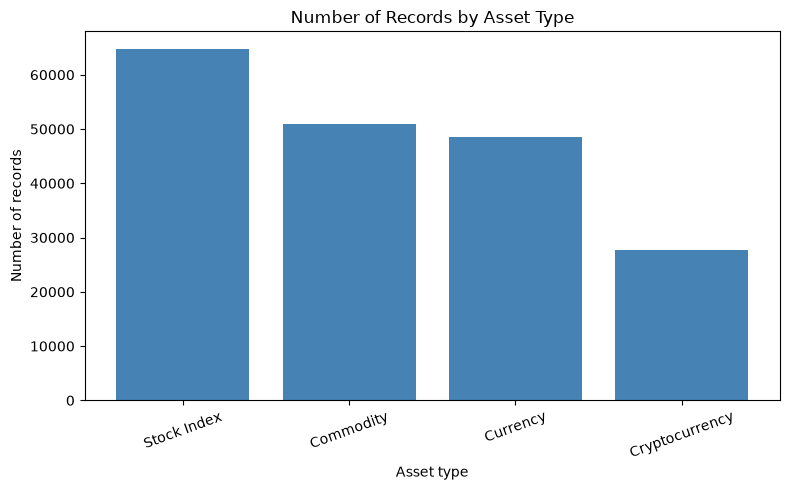

In [8]:
asset_type_counts = df["asset_type"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(asset_type_counts.index, asset_type_counts.values, color="steelblue")
plt.title("Number of Records by Asset Type")
plt.xlabel("Asset type")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

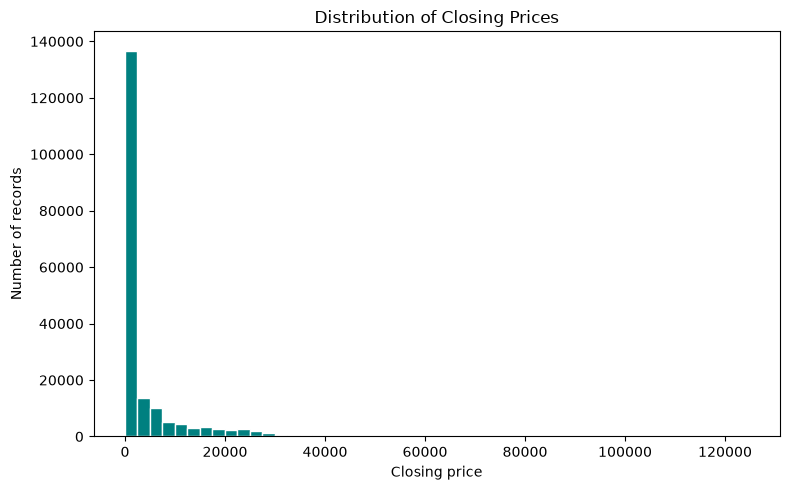

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df["close"], bins=50, color="teal", edgecolor="white")
plt.title("Distribution of Closing Prices")
plt.xlabel("Closing price")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

In [11]:
import seaborn as sns

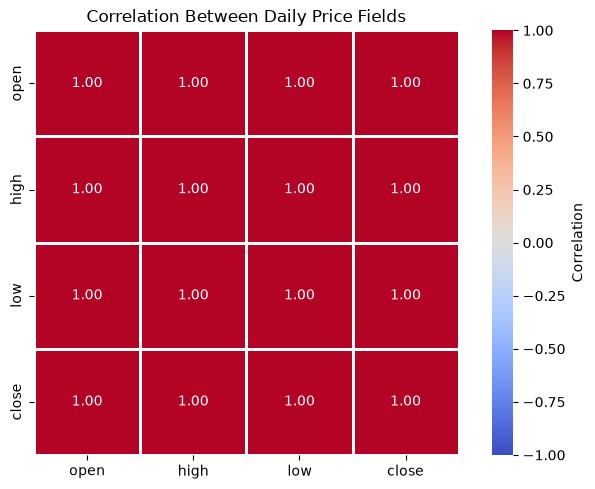

In [12]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,        # print each correlation value in its square
    fmt=".2f",          # show two decimal places
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,        # make each cell square-shaped
    linewidths=1,       # add borders between cells
    linecolor="white",
    cbar_kws={"label": "Correlation"}
)

plt.title("Correlation Between Daily Price Fields")
plt.tight_layout()
plt.show()

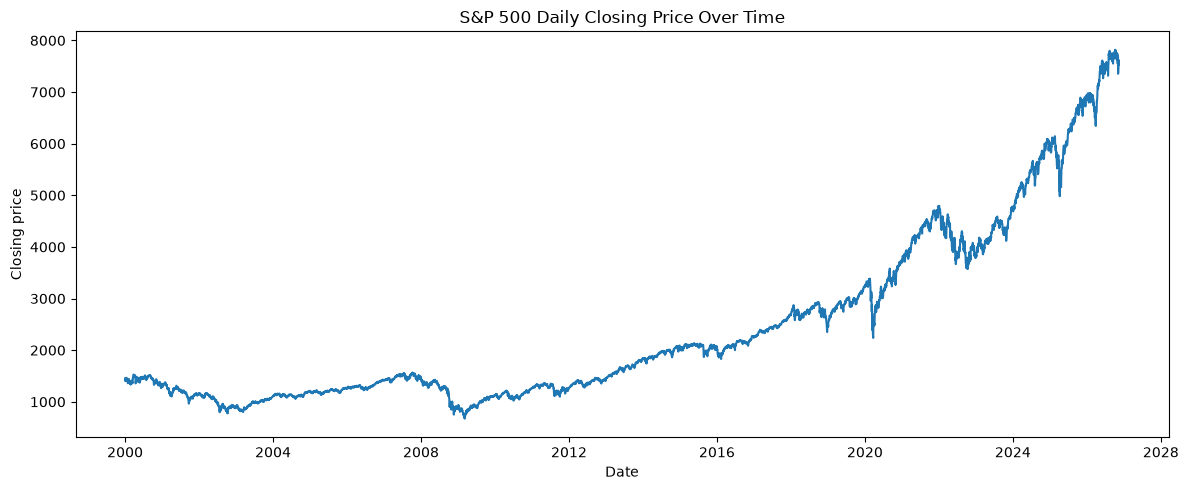

In [13]:
sp500 = df[df["symbol"] == "^GSPC"].sort_values("date")

plt.figure(figsize=(12, 5))
plt.plot(sp500["date"], sp500["close"])
plt.title("S&P 500 Daily Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing price")
plt.tight_layout()
plt.show()

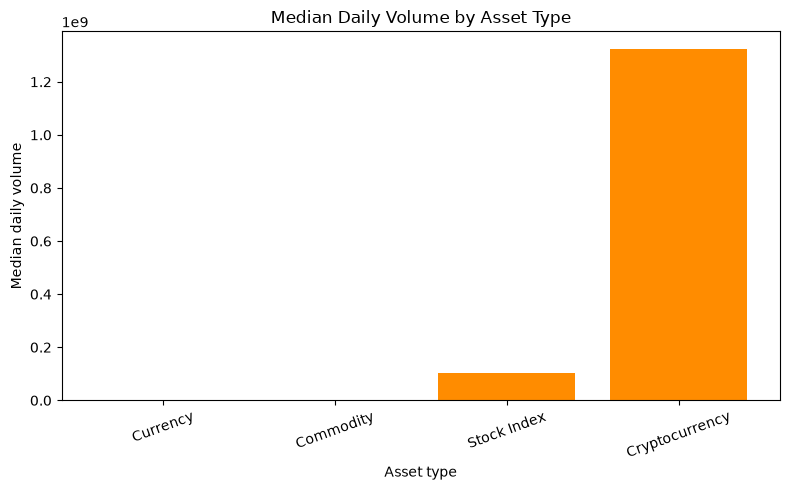

In [14]:
median_volume = df.groupby("asset_type")["volume"].median().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(median_volume.index, median_volume.values, color="darkorange")
plt.title("Median Daily Volume by Asset Type")
plt.xlabel("Asset type")
plt.ylabel("Median daily volume")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

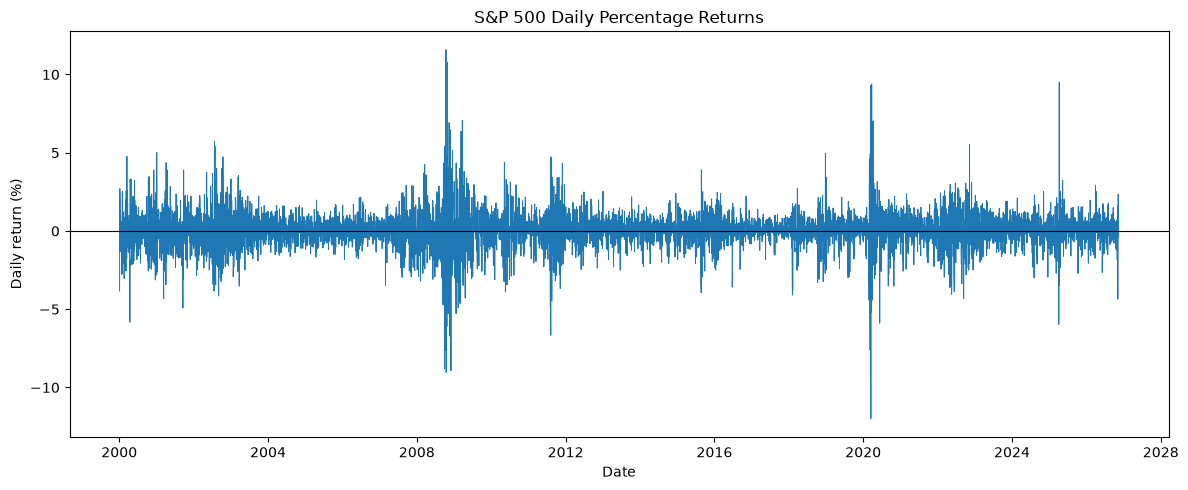

In [15]:
sp500 = sp500.copy()
sp500["daily_return_pct"] = sp500["close"].pct_change() * 100

plt.figure(figsize=(12, 5))
plt.plot(sp500["date"], sp500["daily_return_pct"], linewidth=0.7)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("S&P 500 Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily return (%)")
plt.tight_layout()
plt.show()

# Key Findings

Key Findings
- The dataset contains 192,010 rows and 10 columns, covering daily records from January 3, 2000 to November 13, 2026.
- There are no missing values and no exact duplicate rows.
- Of the four asset types, Stock Index has the most records (64,768); Cryptocurrency has the fewest (27,751). The region column contains only “Global.”
- Closing prices across all assets are strongly right-skewed: most are much lower than the maximum, which is about 124,753. This reflects the mixture of assets with different price scales.
- The open, high, low, and close fields are strongly positively correlated overall. S&P 500 daily returns mostly fluctuate around zero, with periods of larger positive and negative movements.
Data note: The two negative WTI crude oil prices occur on April 20–21, 2020. They are unusual observations worth retaining and mentioning in the analysis, rather than automatically treating them as errors.